# VaR y ES del S&P 500 con Fissler y Ziegel (2016)

El notebook sigue el orden de *Higher order elicitability and Osband's principle* (Fissler y Ziegel, 2016, *The Annals of Statistics* 44(4)). Cada resultado teórico se ilustra con un cálculo y la aplicación usa datos diarios de SPY:

1. Introducción y datos
2. Elicitabilidad de orden superior: definiciones y resultados básicos
3. Principio de Osband
4. Funcionales con componentes elicitables: el VaR y su backtesting
5. Medidas de riesgo espectrales: el par (VaR, ES) y el score FZ0
6. Discusión

Las funciones están en `var_es.py` (cálculos) y `graficos.py` (figuras). El notebook solo las ejecuta. **Resultado teórico** marca propiedades matemáticas; **Hallazgo empírico**, resultados de esta muestra.

In [1]:
import pandas as pd

import graficos as gr
import var_es as ve

pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
pd.set_option("display.width", 160)

## 1. Introducción y datos

El paper parte de un problema práctico: para comparar pronósticos por su score promedio, la función de scoring tiene que ser consistente con lo que se pronostica. El VaR la tiene; el ES, solo junto con el VaR.

**Datos.** Precio de cierre ajustado de SPY (Yahoo Finance) del 2010-01-04 al 2025-12-31. El rendimiento es $Y_t = r_t = 100\ln(P_t/P_{t-1})$ y la pérdida, $L_t = -Y_t$. La estimación cubre 2010–2015 y la evaluación fuera de muestra 2016–2025 (2.514 días). Los datos se guardan en `data/`; si no existen, se descargan.

**Convenciones.** $\alpha$ es la probabilidad de cola ($0{,}05$ y $0{,}01$, es decir, 95 % y 99 % de confianza). En la teoría, como en el paper, el par se escribe $x = (x_1, x_2) = (\mathrm{VaR}_\alpha, \mathrm{ES}_\alpha)$ sobre los rendimientos, con valores negativos. En tablas y gráficas se reportan pérdidas positivas: $v = -x_1$, $e = -x_2$; una excepción es $L_t > v_t$.

In [2]:
price = ve.load_prices()["Close"]
r, L = ve.returns_and_losses(price)
print(f"{price.index[0].date()} a {price.index[-1].date()}: {len(price)} precios, {len(r)} rendimientos")

2010-01-04 a 2025-12-31: 4024 precios, 4023 rendimientos


**Precio y rendimientos.** El panel superior muestra el precio ajustado en escala logarítmica y el inferior, el rendimiento diario. La línea punteada separa la muestra de estimación (2010–2015) de la de evaluación (2016–2025). Interesa ver dos cosas: si la volatilidad cambia en el tiempo, lo que afecta a los modelos con ventana fija, y qué episodios extremos caen en la evaluación.

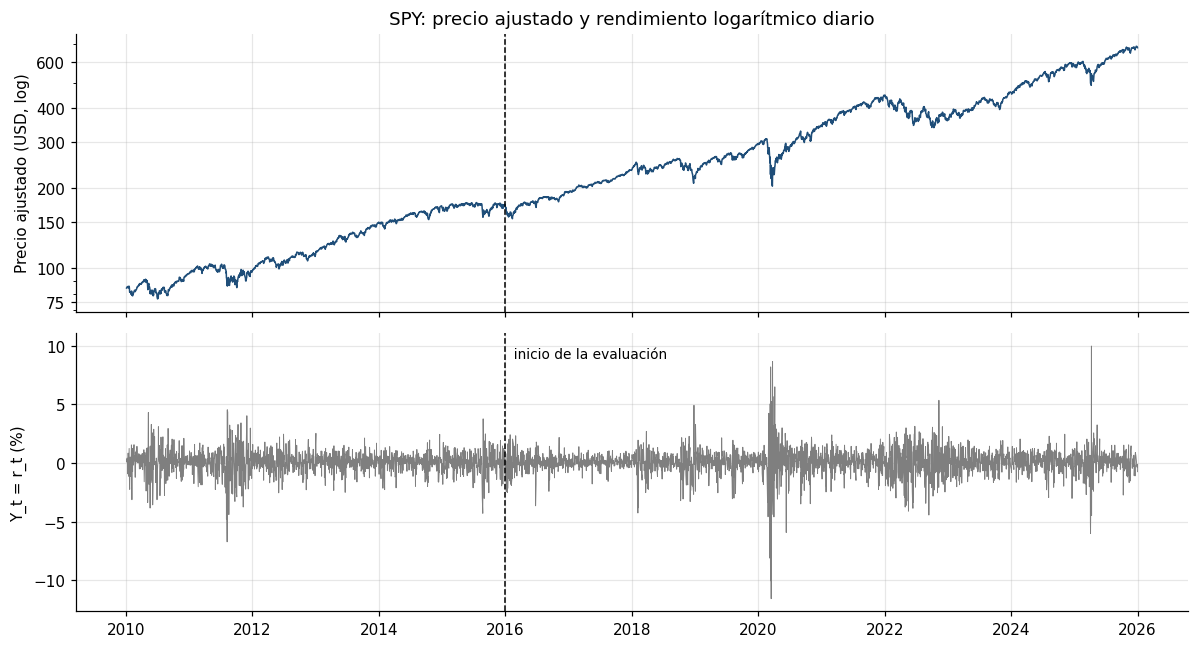

In [3]:
gr.precio_rendimientos(price, r);

**Hallazgo empírico.** La volatilidad se agrupa: 2017 es tranquilo y marzo de 2020, 2022 y abril de 2025 concentran los movimientos extremos. Todos esos episodios caen en la muestra de evaluación.

**Forma de la distribución.** A la izquierda, la densidad empírica de las pérdidas frente a una normal con la misma media y desviación, en escala logarítmica para que las colas se vean. A la derecha, el gráfico QQ contra la normal: si los datos fueran normales, los puntos caerían sobre la recta. Esto anticipa qué tan bien puede funcionar el modelo normal que se usa como competidor.

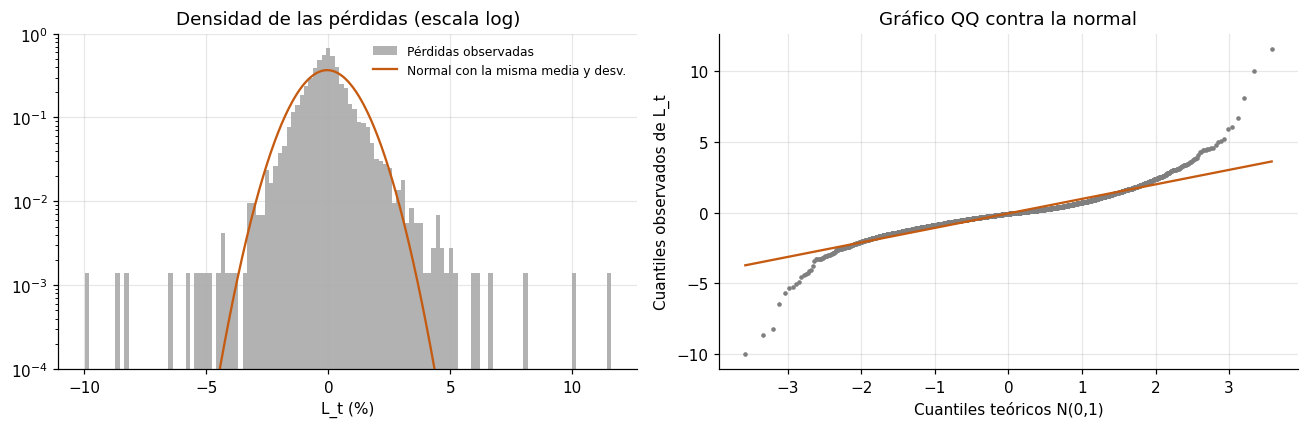

In [4]:
gr.distribucion_perdidas(L);

**Hallazgo empírico.** Las colas son mucho más pesadas que las de la normal, sobre todo la de pérdidas: los puntos del QQ se separan de la recta a partir de unos dos cuantiles teóricos.

In [5]:
display(ve.descriptivas(r).to_frame("Rendimientos 2010-2025"))
ve.tail_table(L)

,Rendimientos 2010-2025
N,"4,023.0000"
Media,0.0518
Desv. estándar,1.0863
Vol. anualizada,17.2448
Mínimo,-11.5887
Percentil 1,-3.1238
Percentil 5,-1.6665
Percentil 95,1.5379
Percentil 99,2.6370
Máximo,9.9863


,Empírico,Normal
Cuantil 95% de L,1.6667,1.7351
Cuantil 99% de L,3.1352,2.4754
Días con L > 4%,20.0000,0.3855
Días con L > 5%,8.0000,0.0067


La curtosis en exceso es 12,5 y Jarque-Bera rechaza la normalidad. La normal sobreestima levemente el cuantil de 95 % (1,74 frente a 1,67) y subestima el de 99 % (2,48 frente a 3,14). Hubo 8 pérdidas superiores al 5 %; la normal esperaría 0,007.

## 2. Elicitabilidad de orden superior

### 2.1 Notación y definiciones

Sea $T: \mathcal{F} \to A \subseteq \mathbb{R}^k$ un funcional. Una función de scoring $S(x, y)$ penaliza el reporte $x$ cuando se observa $y$, y su score esperado es $\bar S(x, F) = E_F[S(x, Y)]$. $S$ es **estrictamente $\mathcal{F}$-consistente** para $T$ si $t = T(F)$ es el único minimizador de $\bar S(\cdot, F)$, y $T$ es **$k$-elicitable** si existe tal $S$. Una función de identificación $V$ cumple $\bar V(x, F) = 0$ si y solo si $x = T(F)$.

Con $F$ la distribución de $Y$:

$$
\mathrm{VaR}_\alpha(F) = F^{-1}(\alpha), \qquad \mathrm{ES}_\alpha(F) = \frac{1}{\alpha}\int_0^\alpha F^{-1}(u)\,du .
$$

La consistencia es lo que hace interpretable un ranking: si $S$ es estrictamente consistente, reportar el verdadero $T(F)$ minimiza el score esperado, y el score promedio realizado lo estima.

### 2.2 Resultados básicos

**Resultado teórico: el VaR es 1-elicitable.** La pinball loss $S(x, y) = (\mathbf{1}\{y \le x\} - \alpha)\,g(x) - \mathbf{1}\{y \le x\}\,g(y)$, con $g$ estrictamente creciente, cumple $\bar S(x, F) - \bar S(t, F) = \int_t^x (F(y) - \alpha)\,g'(y)\,dy > 0$ para $x \ne t$.

**Resultado teórico: el ES no es 1-elicitable.** Si $T$ es elicitable, sus conjuntos de nivel $M_t = \{F : T(F) = t\}$ son convexos: como $\bar S$ es lineal en $F$, si $t$ es óptimo para $F_0$ y $F_1$, también lo es para $F_\lambda = (1-\lambda)F_0 + \lambda F_1$. El ES rompe esta condición porque el cuantil de la mezcla no es lineal en $\lambda$, y ese cuantil es la frontera de la cola que se promedia.

**Contraejemplo discreto ($\alpha = 0{,}5$).** $F_0$ toma $\{-10, -6\}$ con probabilidades $\{0{,}5; 0{,}5\}$ y $F_1$ toma $\{-16, -4, 10\}$ con $\{0{,}25; 0{,}25; 0{,}5\}$. Ambas tienen $\mathrm{ES}_{0.5} = -10$. El gráfico recorre todas las mezclas $F_\lambda$ y calcula su VaR (izquierda) y su ES (derecha), con el ES discreto $\frac{1}{\alpha}\big[E[Y\mathbf{1}\{Y < x_1\}] + x_1(\alpha - P(Y < x_1))\big]$. Si el ES fuera elicitable, la curva de la derecha sería plana en $-10$.

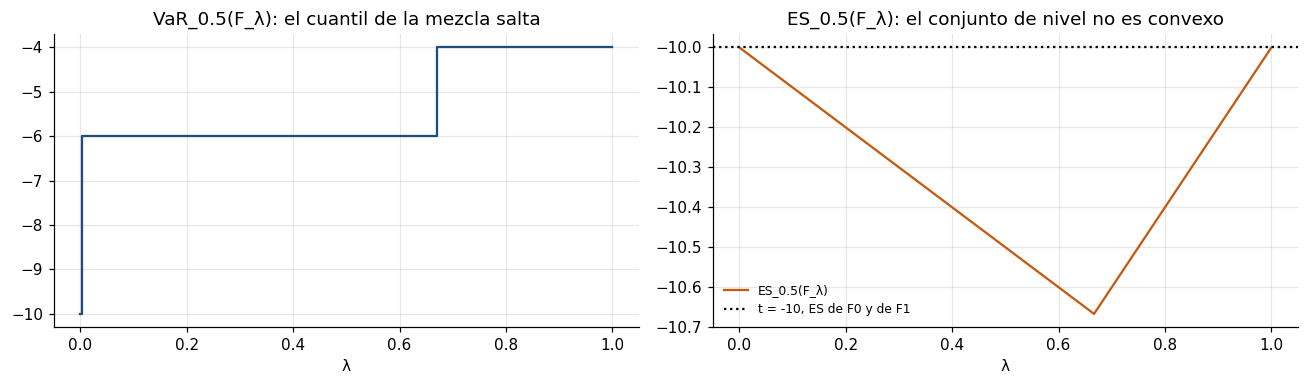

In [6]:
gr.mezcla_discreta();

**Resultado teórico ilustrado.** Para todo $\lambda \in (0,1)$ el cuantil de la mezcla salta a $-6$ o $-4$ y el ES se aleja de $-10$ (llega a $-10{,}67$ en $\lambda = 2/3$). El conjunto de nivel no es convexo, así que el ES no es 1-elicitable.

**Distribuciones continuas.** Se repite el ejercicio con $\alpha = 0{,}05$ y tres parejas, siempre mezclando con $F_1 = N(0,1)$: $F_2 = N(-1{,}031;\ 0{,}5^2)$ tiene el mismo ES; $F_3 = N(-0{,}822;\ 0{,}5^2)$, el mismo VaR; $F_4$, una $t_4$ desplazada y escalada, el mismo VaR **y** el mismo ES. Para cada mezcla, el VaR se obtiene resolviendo $F(x_1) = \alpha$ y el ES con $\mathrm{ES}_\alpha = x_1 - \frac{1}{\alpha}\int_{-\infty}^{x_1} F(y)\,dy$, la identidad que reaparece en la prueba del Corolario 5.5.

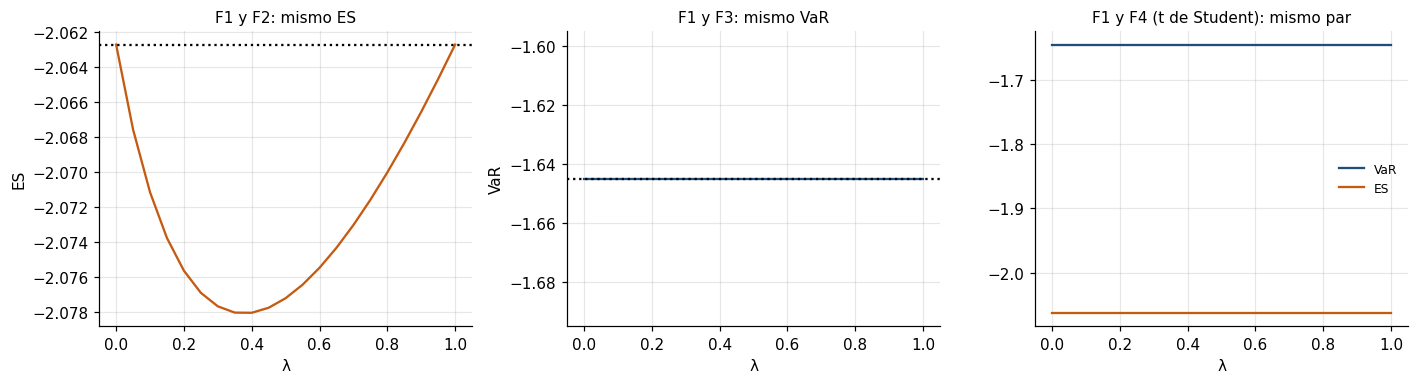

In [7]:
camino = ve.camino_mezclas()
gr.mezclas_continuas(camino);

**Resultado teórico ilustrado.** Mezclar distribuciones con el mismo ES cambia el ES (panel izquierdo), mientras que el VaR (centro) y el par (VaR, ES) (derecha) se conservan. El par cumple la condición necesaria que el ES solo no cumple.

## 3. Principio de Osband

**Resultado teórico (Teorema 3.2).** Si $S$ es estrictamente consistente y $V$ es una función de identificación estricta, existe una matriz $h(x)$ tal que $\nabla_x \bar S(x, F) = h(x)\,\bar V(x, F)$. La idea: en cada $x$, toda $F$ con $\bar V(x, F) = 0$ tiene $\nabla_x \bar S(x, F) = 0$, de modo que el gradiente es combinación lineal de las componentes de $\bar V$. La simetría del Hessiano de $\bar S$ restringe luego la forma de $h$ y, con ella, la de toda la familia de scores.

Para (VaR, ES), la función de identificación es

$$
V(x, y) = \Big(\mathbf{1}\{y \le x_1\} - \alpha,\ \ x_2 - x_1 + \tfrac{1}{\alpha}\mathbf{1}\{y \le x_1\}(x_1 - y)\Big),
$$

y para la familia del Corolario 5.5 resulta $h(x) = \mathrm{diag}\big(G_1'(x_1) + G_2(x_2)/\alpha,\ G_2'(x_2)\big)$.

**Verificación del principio.** Se toma $Y \sim t_4$ (localización $-0{,}05$, escala $0{,}8$) y el score FZ0 de la sección 5. En 40 reportes $x$ al azar dentro de $A_0 = \{x_1 \ge x_2\}$ se calcula el gradiente de $\bar S$ por diferencias finitas y se compara con $h(x)\bar V(x, F)$, donde $\bar V$ se obtiene por integración. Si el teorema se cumple, los puntos caen sobre la diagonal.

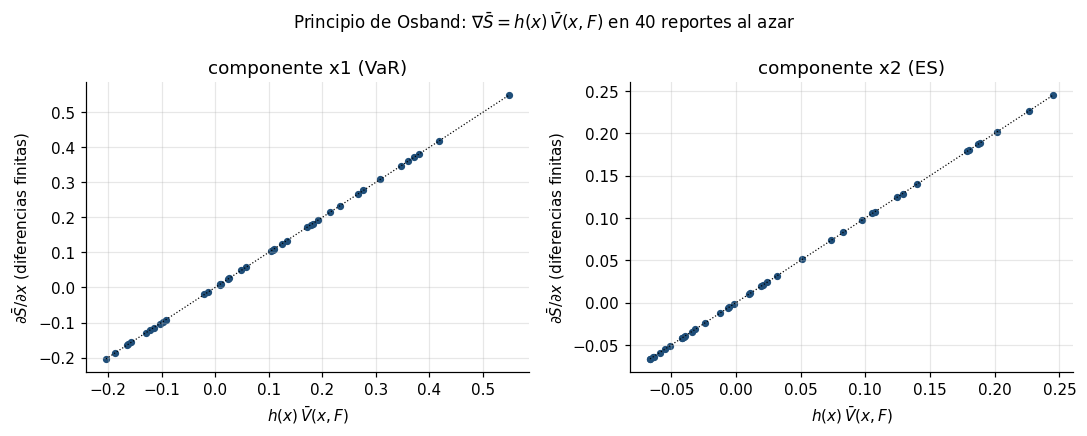

In [8]:
gr.osband(ve.osband_check(40));

**Resultado teórico ilustrado.** Los 40 puntos caen sobre la diagonal en ambas componentes: el gradiente del score esperado es exactamente $h(x)\bar V(x, F)$, con $h$ diagonal.

## 4. Funcionales con componentes elicitables: el VaR

La sección 4 del paper trata funcionales cuyas componentes son elicitables una por una, como el VaR en varios niveles. En la aplicación, el VaR al 95 % y al 99 % son esas componentes: se pueden estimar y evaluar por separado. La primera componente de $V$, $\mathbf{1}\{y \le x_1\} - \alpha$, es la base del backtesting clásico.

**Dos modelos con la misma información** (ventana móvil de 500 días, pronóstico a un día):

- **Simulación histórica (HS):** $\hat v = L_{(k)}$ con $k = \lceil n(1-\alpha)\rceil$, y $\hat e = \frac{1}{\alpha}\big[\frac{1}{n}\sum_i L_i\mathbf{1}\{L_i > \hat v\} + \hat v\,(F_n(\hat v) - (1-\alpha))\big]$. El segundo término reparte la masa ubicada en el cuantil (Acerbi y Tasche, 2002).
- **Normal paramétrico:** $v = \hat\mu + \hat\sigma z_{1-\alpha}$ y $e = \hat\mu + \hat\sigma\,\varphi(z_{1-\alpha})/\alpha$, con media y desviación de la misma ventana.

In [9]:
fc, L_eval = ve.rolling_forecasts(L)
ve.resumen_pronosticos(fc)

Media  Mínimo  Máximo
HS     95% VaR 1.7117  0.8288  2.5901
           ES  2.6868  1.3052  4.3294
       99% VaR 3.1553  1.4480  4.9977
           ES  4.4145  2.2497  8.1821
Normal 95% VaR 1.7320  0.8651  2.6872
           ES  2.1845  1.1081  3.3784
       99% VaR 2.4699  1.2614  3.8146
           ES  2.8369  1.4585  4.3751

**Pronósticos.** Cada panel muestra la pérdida realizada (gris) y los pronósticos de VaR (línea continua) y ES (línea punteada) de ambos modelos. El eje se recorta en −6 % para enfocar la cola de pérdidas. Lo que se busca es dónde difieren los modelos: en el VaR, en el ES o en ambos, y cómo reaccionan a los episodios de estrés.

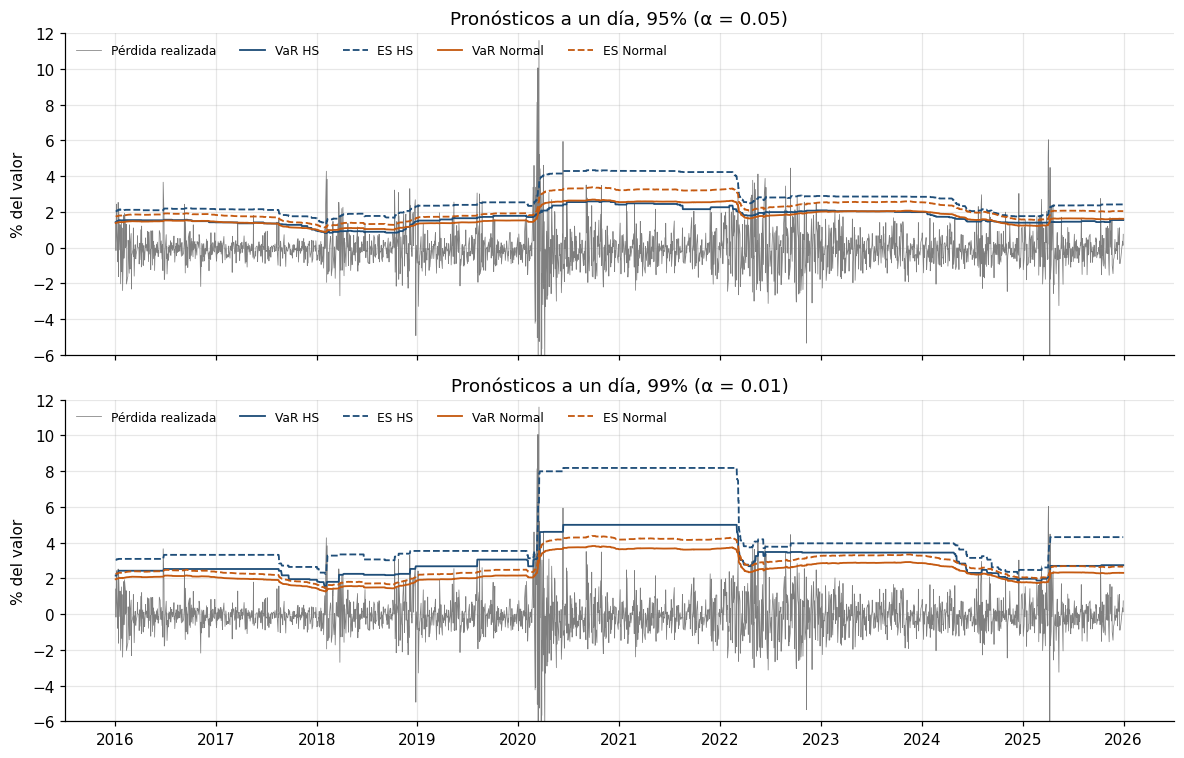

In [10]:
gr.pronosticos(fc, L_eval, models=("HS", "Normal"));

**Hallazgo empírico.** Al 95 % los dos VaR casi se superponen y la diferencia está en el ES: el normal promedia 2,18 % frente a 2,69 % de HS. Al 99 % el normal queda por debajo en VaR (2,47 frente a 3,16) y en ES (2,84 frente a 4,41). HS cambia a saltos y arrastra pérdidas extremas durante 500 días: su ES al 99 % se queda en 8,18 % desde marzo de 2020 hasta marzo de 2022.

**Backtesting (calibración absoluta).** Las excepciones $I_t = \mathbf{1}\{L_t > \hat v_t\}$ deberían ser i.i.d. Bernoulli($\alpha$). Kupiec (1995) contrasta la tasa con $LR_{uc} = -2\ln\frac{(1-\alpha)^{T-x}\alpha^x}{(1-\hat\pi)^{T-x}\hat\pi^x} \sim \chi^2_1$. Christoffersen (1998) contrasta además la independencia con una cadena de Markov ($\hat\pi_{01}$: probabilidad de excepción tras un día sin excepción; $\hat\pi_{11}$: tras un día con excepción) y la cobertura condicional con $LR_{cc} \sim \chi^2_2$. El gráfico marca en rojo las excepciones del VaR de HS.

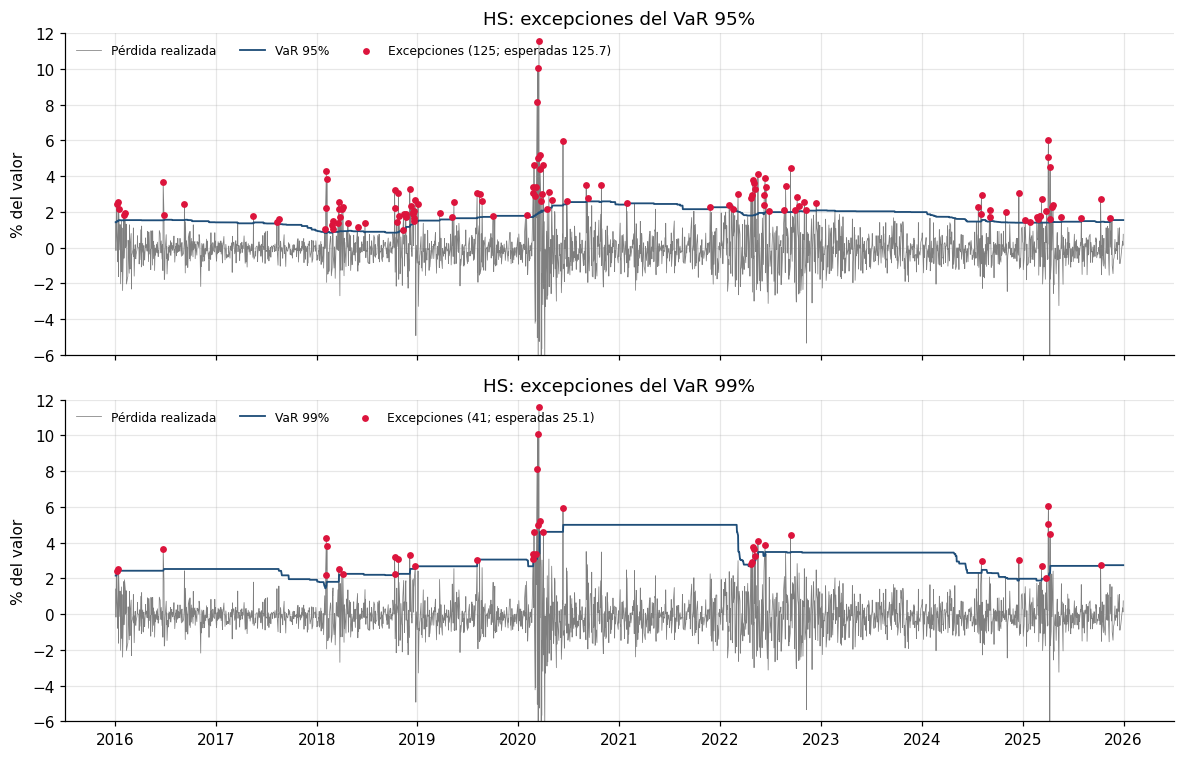

In [11]:
gr.excepciones(fc, L_eval, "HS");

**Hallazgo empírico.** Las excepciones no se reparten en el tiempo: se agrupan en 2018, marzo de 2020, 2022 y abril de 2025, y desaparecen en 2017, 2021 y 2023.

In [12]:
bt, nulls = ve.backtest_table(fc, L_eval)
bt[["excepciones", "esperadas", "tasa", "p Kupiec", "p binomial exacta", "pi01", "pi11",
    "p independencia", "p condicional", "p independencia MC"]]

excepciones  esperadas   tasa  p Kupiec  p binomial exacta   pi01   pi11  p independencia  p condicional  p independencia MC
HS     95%     125.0000   125.7000 0.0497    0.9489             1.0000 0.0444 0.1520           0.0000         0.0000              0.0001
       99%      41.0000    25.1400 0.0163    0.0036             0.0034 0.0146 0.1220           0.0004         0.0000              0.0001
Normal 95%     128.0000   125.7000 0.0509    0.8338             0.8190 0.0449 0.1562           0.0000         0.0000              0.0001
       99%      71.0000    25.1400 0.0282    0.0000             0.0000 0.0250 0.1408           0.0000         0.0000              0.0000

Al 95 % ambos modelos aciertan la tasa (HS 4,97 %, normal 5,09 %; Kupiec p = 0,95 y 0,83). Al 99 % ambos la fallan, HS bastante menos (1,63 % frente a 2,82 %). Christoffersen rechaza la independencia en los cuatro casos: tras una excepción, la probabilidad de otra sube a 12–16 %. Los p-valores exactos y de Monte Carlo coinciden con los asintóticos.

**Excepciones por año.** Barras de excepciones de cada modelo por año frente a las esperadas ($\alpha \times$ días del año, línea negra). Un modelo condicionalmente calibrado oscilaría alrededor de la línea; uno que ignora el agrupamiento de volatilidad se excede en los años turbulentos y se queda corto en los tranquilos.

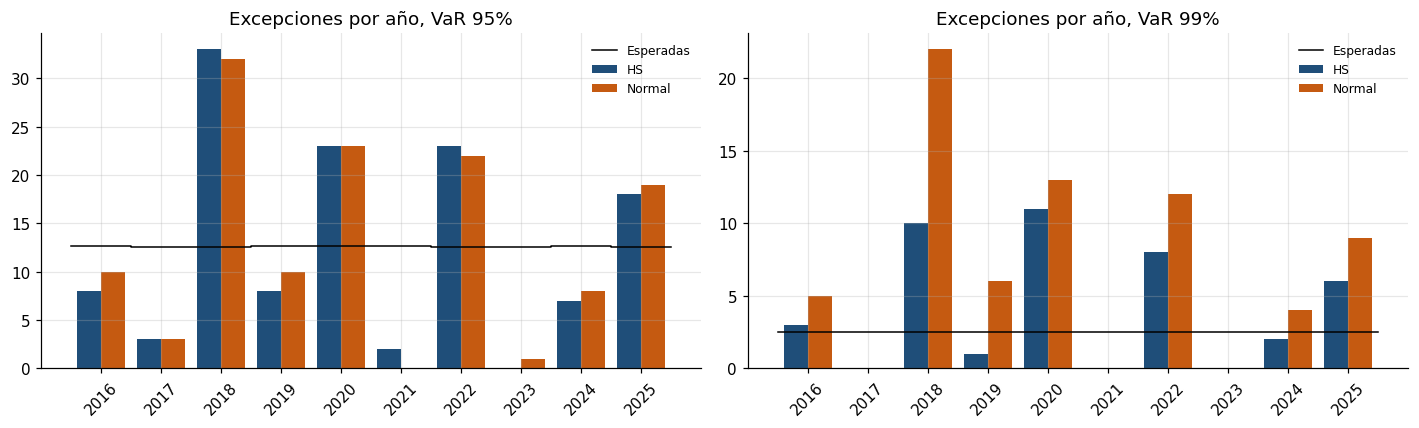

In [13]:
gr.excepciones_por_anio(ve.hits_by_year(fc, L_eval));

**Hallazgo empírico.** El total de diez años parece correcto al 95 % solo porque los excesos de 2018, 2020 y 2022 compensan los déficits de 2017, 2021 y 2023. Al 99 % el normal se dispara en los años de estrés (22 excepciones en 2018, cuando se esperaban 2,5).

## 5. Medidas de riesgo espectrales: el par (VaR, ES)

**Resultado teórico (Corolario 5.5).** En $A_0 = \{x_1 \ge x_2\}$,

$$
S(x_1, x_2, y) = (\mathbf{1}\{y \le x_1\} - \alpha)G_1(x_1) - \mathbf{1}\{y \le x_1\}G_1(y) + G_2(x_2)\Big(x_2 - x_1 + \tfrac{1}{\alpha}\mathbf{1}\{y \le x_1\}(x_1 - y)\Big) - \mathcal{G}_2(x_2) + a(y)
$$

es estrictamente consistente para $(\mathrm{VaR}_\alpha, \mathrm{ES}_\alpha)$ si $G_1$ es creciente y $\mathcal{G}_2$ es estrictamente creciente y estrictamente convexa, con $\mathcal{G}_2' = G_2$. El par es 2-elicitable.

**Score usado: FZ0** (Patton, Ziegel y Chen, 2019), con $G_1 \equiv 0$ y $\mathcal{G}_2(x_2) = -\ln(-x_2)$. En pérdidas:

$$
S_{FZ0}(v, e, L) = \frac{\mathbf{1}\{L > v\}(L - v)}{\alpha\,e} + \frac{v}{e} + \ln e - 1 .
$$

El primer término castiga cada exceso sobre el VaR en proporción al ES reportado; $v/e + \ln e$ cobra un poco todos los días por reportar un ES alto. FZ0 es homogéneo de grado cero, así que las diferencias entre modelos no dependen de la escala.

**Idea de la prueba: $\bar S(x, F) - \bar S(t, F) = R_1 + R_2$.** $R_1$ es la pinball loss ponderada por $G_1$ (cero en FZ0). Integrando por partes, $E[\mathbf{1}\{Y \le x_1\}(x_1 - Y)] = \int_{-\infty}^{x_1}F(y)\,dy$, y queda $R_2 = d_{\mathcal{G}_2}(t_2, x_2) + \frac{G_2(x_2)}{\alpha}\int_{t_1}^{x_1}(F(y) - \alpha)\,dy$: una distancia de Bregman más un término cruzado, ambos no negativos. Con la $t_4$ de la sección 3, el gráfico compara, en 40 reportes al azar, la diferencia de score calculada directamente con $R_1 + R_2$ (izquierda) y muestra el peso de cada término (derecha).

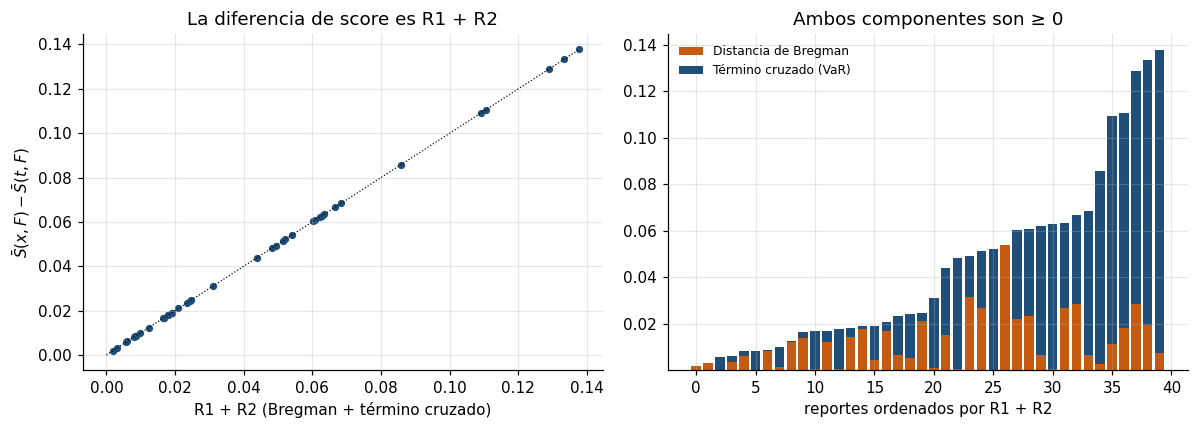

In [14]:
gr.descomposicion_r(ve.descomposicion_check(40));

**Resultado teórico ilustrado.** La diferencia de score coincide con $R_1 + R_2$ en todos los reportes y ambos términos son no negativos: el mínimo único está en $t$.

**Forma del score esperado.** Curvas de nivel de $\bar S_{FZ0}(x, F)$ para la misma $t_4$ (izquierda) y cortes por el valor verdadero (derecha). La línea punteada es el mejor $x_2$ para cada $x_1$, que resuelve $\bar V_2 = 0$. Cerca de $t_1$ esa curva es plana: el término $\frac{1}{\alpha}\mathbf{1}\{y \le x_1\}(x_1 - y)$ hace que un error pequeño en el VaR afecte al ES solo en segundo orden.

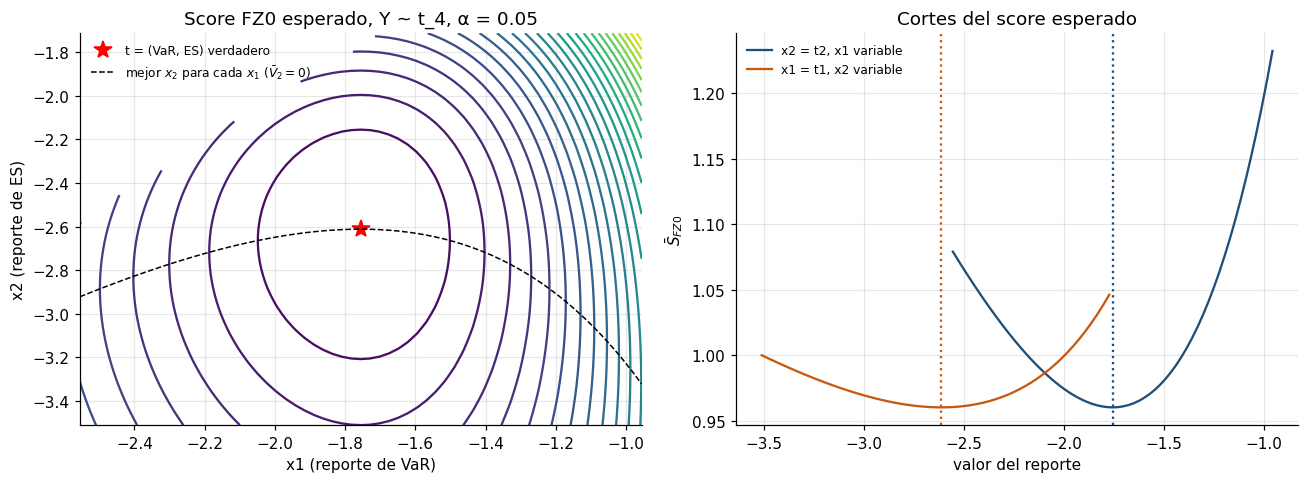

In [15]:
gr.superficie(ve.superficie_fz0());

**Resultado teórico ilustrado.** Hay un único mínimo en $t = (-1{,}76;\ -2{,}61)$, y reportar un VaR o un ES menos extremo que el verdadero cuesta más que exagerarlo en la misma magnitud.

**M-estimación.** Minimizar el score empírico $\frac{1}{n}\sum_i S(x, y_i)$ da M-estimadores. En la primera ventana de 500 días (2014–2015), para cada VaR $v$ se calcula el ES óptimo y el FZ0 promedio resultante. Si HS es el M-estimador de FZ0, el mínimo del perfil debe estar en el VaR de HS y el ES óptimo debe ser el de HS.

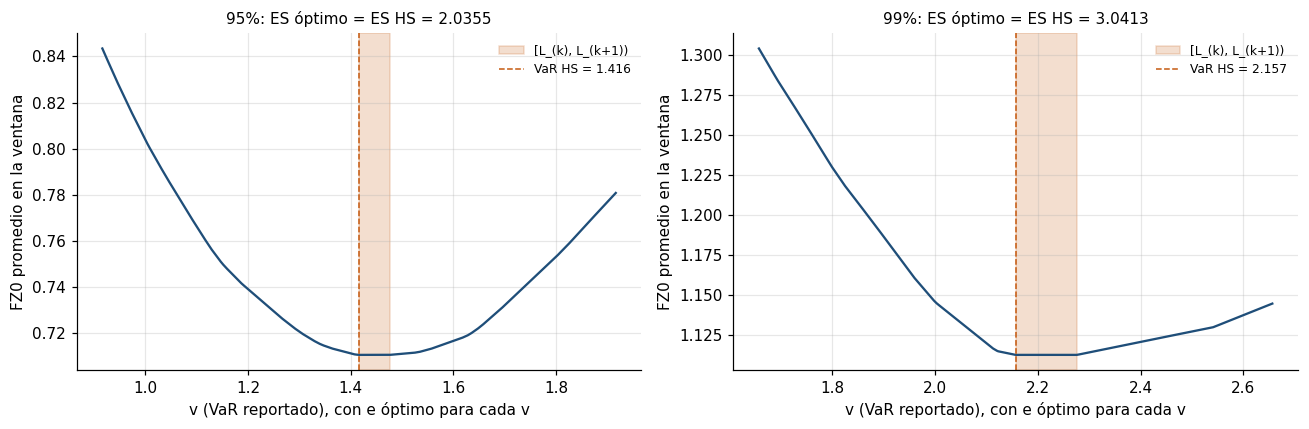

In [16]:
pos0 = (L.index >= ve.OOS_START).argmax()
w0 = L.iloc[pos0 - ve.WINDOW: pos0]
gr.perfil_mestimacion({a: ve.empirical_fz0_profile(w0, a) for a in ve.LEVELS});

**Resultado teórico ilustrado.** El perfil es plano en todo el intervalo $[L_{(k)}, L_{(k+1)})$, que es el conjunto de $\alpha$-cuantiles de la distribución empírica, y HS toma su extremo izquierdo. El ES óptimo coincide con el de HS: la simulación histórica es el M-estimador de FZ0.

**Ranking de modelos.** Con el diferencial $\Delta S_t = S_{FZ0}(\text{HS}) - S_{FZ0}(\text{Normal})$, la prueba de Diebold y Mariano (1995) contrasta $E[\Delta S_t] = 0$ con $DM = \overline{\Delta S}/\sqrt{\hat\sigma^2_{HAC}/T}$, usando Newey-West con 8 rezagos. Con ventanas móviles de tamaño fijo se interpreta como en Giacomini y White (2006). $DM < 0$ favorece a HS.

In [17]:
scores = ve.scores_fz0(fc, L_eval)
ve.score_table(scores)

,FZ0 HS,FZ0 Normal,media ΔS,rezagos,DM,p bilateral,p unilateral,% días HS mejor
95%,1.0928,1.1723,-0.0795,8.0000,-2.5043,0.0123,0.0061,0.2271
99%,1.7489,2.3317,-0.5827,8.0000,-2.7797,0.0054,0.0027,0.0278


HS tiene menor score en ambos niveles: 1,093 frente a 1,172 al 95 % ($DM = -2{,}50$, p = 0,012) y 1,749 frente a 2,332 al 99 % ($DM = -2{,}78$, p = 0,005). Aun así, el normal puntúa mejor en el 77 % de los días al 95 %.

**Dónde se gana el ranking.** Suma acumulada de $\Delta S_t$ en el tiempo: cada tramo descendente es un periodo en que HS acumula ventaja y cada tramo ascendente, uno en que la acumula el normal.

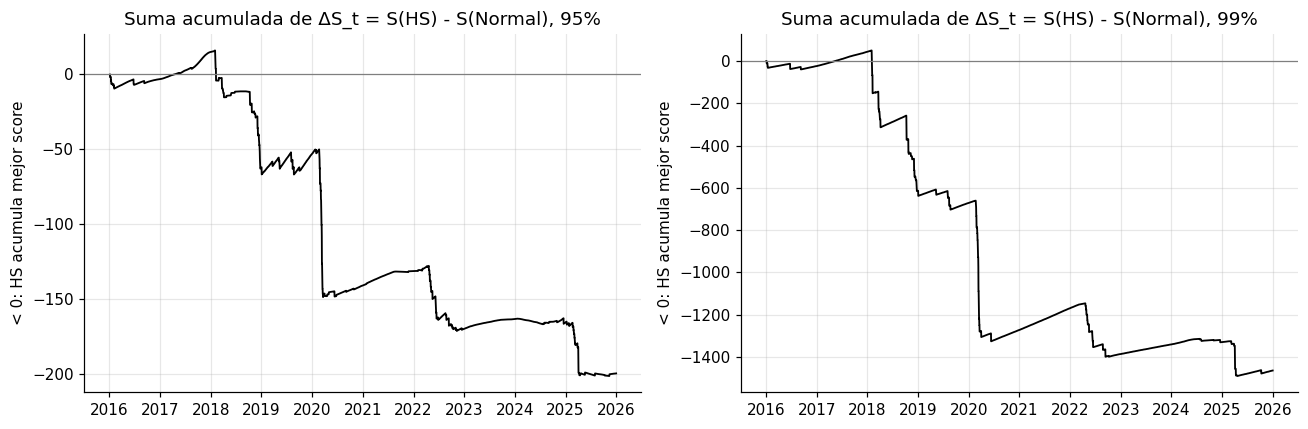

In [18]:
gr.delta_acumulado(scores);

**Hallazgo empírico.** La ventaja de HS se gana a saltos en febrero y el cuarto trimestre de 2018, marzo de 2020, 2022 y abril de 2025. Entre esos episodios, el normal recupera terreno lentamente.

**Por qué.** El score medio de cada modelo se divide en el aporte de sus días sin excepción y el de sus días con excepción. Ahí se ve el compromiso que impone FZ0: un ES bajo ahorra un poco cada día tranquilo, pero cada excepción cuesta en proporción a $1/e$.

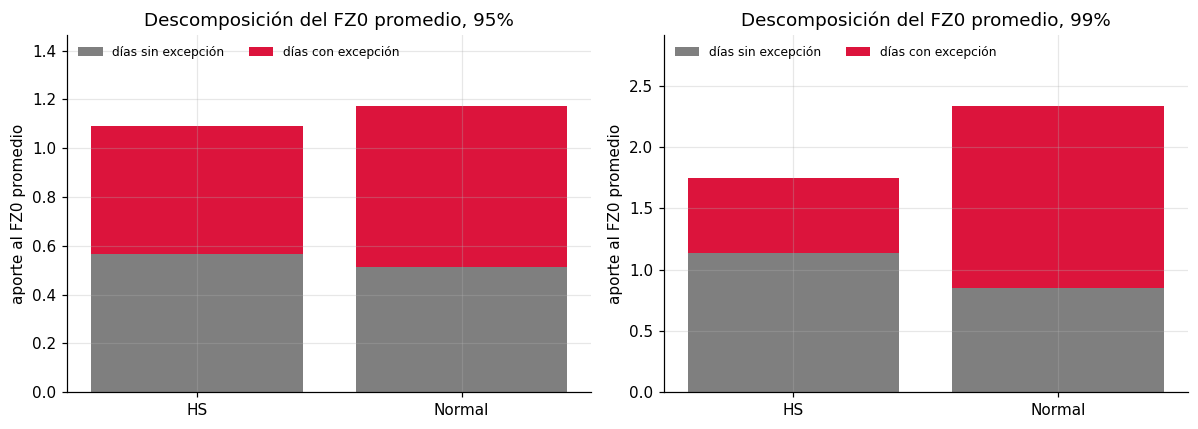

In [19]:
dec = ve.score_decomposition(scores, fc, L_eval)
gr.descomposicion_score(dec);

**Hallazgo empírico.** El normal gana en los días tranquilos y pierde en las excepciones: al 99 %, sus 71 excepciones aportan 1,48 de sus 2,33 puntos, frente a 0,61 de 1,75 en HS. La razón de fondo está en la tabla siguiente.

In [20]:
ve.es_ratio(fc, L_eval)

Pérdida media en excepción  ES medio reportado  Razón
HS     95%                      2.7282              2.4646 1.1070
       99%                      3.9998              3.7740 1.0598
Normal 95%                      2.6685              1.9031 1.4022
       99%                      3.2992              2.3672 1.3937

Cuando se supera el VaR normal, la pérdida media es un 40 % mayor que su ES; en HS, entre 6 % y 11 %.

**Por año.** $\Delta S_t$ promedio de cada año (azul cuando gana HS). Sirve para ver si la ventaja es estable o depende de pocos años.

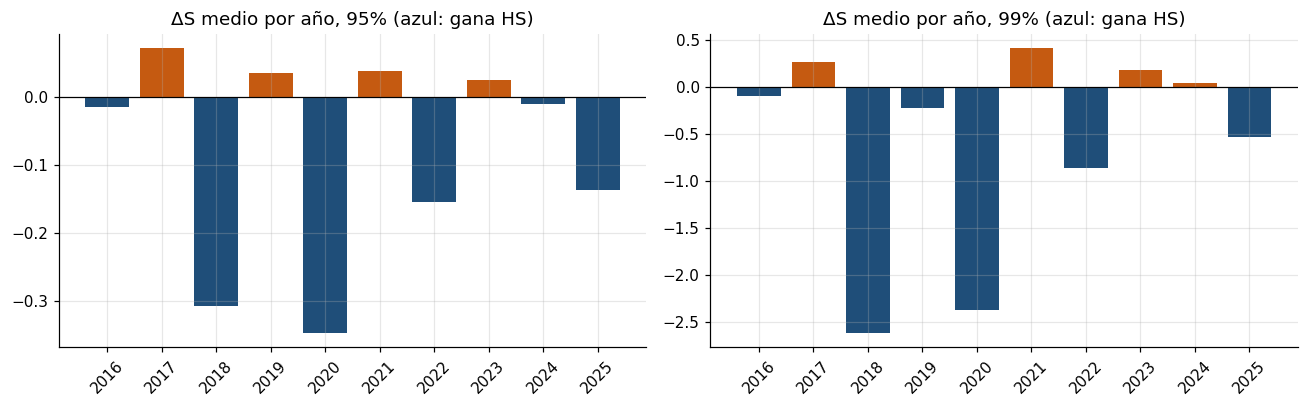

In [21]:
gr.delta_anual(scores);

**Hallazgo empírico.** HS gana en los años de estrés (2018, 2020, 2022, 2025) y el normal en los tranquilos (2017, 2019, 2021, 2023). Al 99 %, las ventajas de HS son un orden de magnitud mayores que las del normal.

**Robustez.** El estadístico DM se recalcula cambiando el número de rezagos HAC, excluyendo periodos, quitando los 10 días más favorables a HS y usando otro miembro de la familia del Corolario 5.5 ($G_1(x) = x$, que suma la pinball loss del VaR). Las barras azules son significativas al 5 %; la línea punteada marca −1,96.

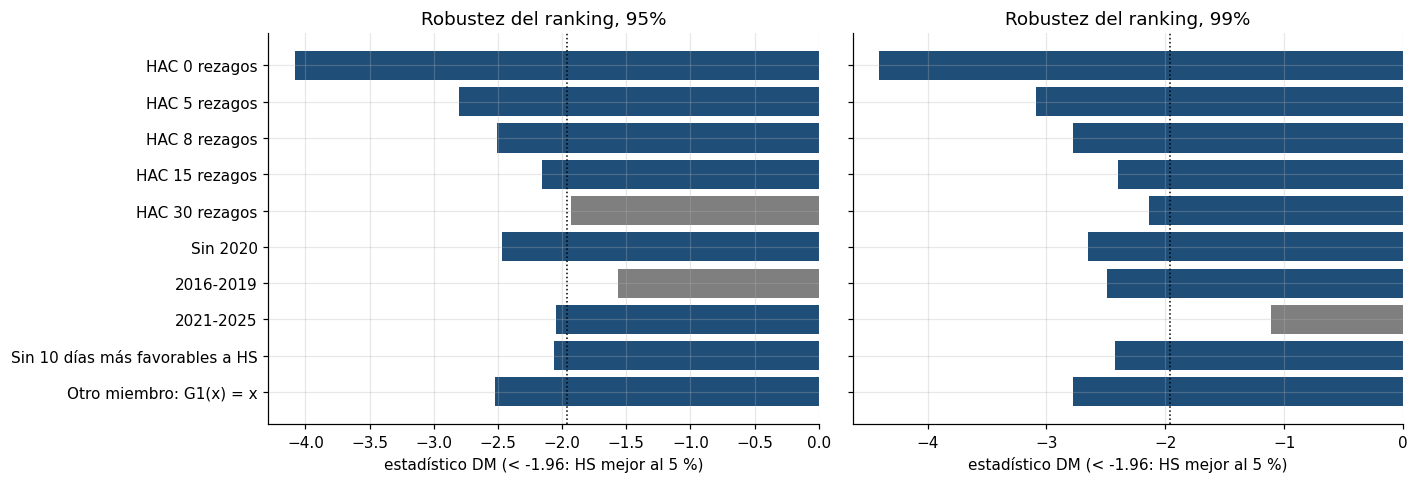

In [22]:
gr.robustez(ve.robustness(scores, fc, L_eval));

**Hallazgo empírico.** Al 99 % el ranking es robusto en todos los casos salvo 2021–2025. Al 95 % es más frágil: pierde significancia con 30 rezagos y en 2016–2019. El orden de los modelos no cambia con el otro miembro de la familia.

## 6. Discusión

In [23]:
ve.final_table(fc, bt, scores, L)

Simulación histórica  Normal paramétrico
Indicador                             Detalle                                                            
VaR 95%                               promedio fuera de muestra                1.7117              1.7320
                                      pronóstico 2026-01-02                    1.5385              1.6084
VaR 99%                               promedio fuera de muestra                3.1553              2.4699
                                      pronóstico 2026-01-02                    2.7400              2.3078
ES 95%                                promedio fuera de muestra                2.6868              2.1845
                                      pronóstico 2026-01-02                    2.4139              2.0372
ES 99%                                promedio fuera de muestra                4.4145              2.8369
                                      pronóstico 2026-01-02                    4.3097              2.6556
Tasa de excepciones                   95%                                      0.0497              0.0509
                                      99%                                      0.0163              0.0282
Kupiec, p-valor                       95%                                      0.9489              0.8338
                                      99%                                      0.0036              0.0000
Christoffersen independencia, p-valor 95%                                      0.0000              0.0000
                                      99%                                      0.0004              0.0000
Christoffersen condicional, p-valor   95%                                      0.0000              0.0000
                                      99%                                      0.0000              0.0000
Score FZ0 promedio                    95%                                      1.0928              1.1723
                                      99%                                      1.7489              2.3317

- **Calibración absoluta (Kupiec, Christoffersen).** Al 95 % ambos modelos aciertan la tasa; al 99 % ambos fallan, HS menos. Ninguno es independiente: las excepciones se agrupan porque ninguno reacciona a la volatilidad reciente. Es una prueba sobre un solo modelo, basada en identificabilidad.
- **Consistencia estadística.** Es una propiedad del score, no de los datos: FZ0 es estrictamente consistente para (VaR, ES) (Corolario 5.5), lo que verificaron las secciones 3 y 5. Garantiza que el ranking premie al mejor pronóstico del par.
- **Precisión predictiva.** HS tiene menor FZ0 promedio en ambos niveles (DM p = 0,012 y 0,005). La ventaja nace en el ES y en los episodios de estrés.
- **Lección.** Al 95 % el backtesting del VaR no separa los modelos; el score conjunto sí, porque la diferencia está en el ES, que no puede evaluarse solo.
- **Limitaciones.** Un activo, una ventana y un horizonte; ambos modelos ignoran el agrupamiento de volatilidad; el ES de HS al 99 % usa 5 observaciones por ventana; la evidencia al 95 % depende de los rezagos HAC.

**Verificaciones independientes.** Cada cálculo se contrasta con una forma alternativa; las mismas comprobaciones corren en `tests/`.

In [24]:
pd.set_option("display.max_colwidth", 80)
ve.verificaciones(L, fc, L_eval, scores).set_index("verificación").style.format("{:.6g}")

,propio,independiente,diferencia abs.
verificación,,,
VaR HS 95%: todas las ventanas vs np.quantile (máx. dif.),0,0,0
ES HS 95%: fórmula con átomo vs integral de la función cuantil,2.03549,2.03549,0
ES normal 95%: fórmula cerrada vs integración numérica,1.72985,1.72985,2.44249e-15
FZ0 95%: forma en pérdidas vs Corolario 5.5 (máx. dif.),1.42109e-14,0,1.42109e-14
VaR HS 99%: todas las ventanas vs np.quantile (máx. dif.),0,0,0
ES HS 99%: fórmula con átomo vs integral de la función cuantil,3.04134,3.04134,0
ES normal 99%: fórmula cerrada vs integración numérica,2.24361,2.24361,2.66454e-15
FZ0 99%: forma en pérdidas vs Corolario 5.5 (máx. dif.),2.84217e-14,0,2.84217e-14
t_4: argmin de E[FZ0] vs VaR verdadero,-1.75548,-1.75548,6.88539e-09


## Referencias

- Acerbi, C. y Tasche, D. (2002). On the coherence of expected shortfall. *Journal of Banking & Finance*, 26(7), 1487–1503.
- Christoffersen, P. F. (1998). Evaluating interval forecasts. *International Economic Review*, 39(4), 841–862.
- Diebold, F. X. y Mariano, R. S. (1995). Comparing predictive accuracy. *Journal of Business & Economic Statistics*, 13(3), 253–263.
- Fissler, T. y Ziegel, J. F. (2016). Higher order elicitability and Osband's principle. *The Annals of Statistics*, 44(4), 1680–1707.
- Giacomini, R. y White, H. (2006). Tests of conditional predictive ability. *Econometrica*, 74(6), 1545–1578.
- Gneiting, T. (2011). Making and evaluating point forecasts. *Journal of the American Statistical Association*, 106(494), 746–762.
- Kupiec, P. H. (1995). Techniques for verifying the accuracy of risk measurement models. *The Journal of Derivatives*, 3(2), 73–84.
- Newey, W. K. y West, K. D. (1987). A simple, positive semi-definite, heteroskedasticity and autocorrelation consistent covariance matrix. *Econometrica*, 55(3), 703–708.
- Osband, K. H. (1985). *Providing incentives for better cost forecasting*. Tesis doctoral, University of California, Berkeley.
- Patton, A. J., Ziegel, J. F. y Chen, R. (2019). Dynamic semiparametric models for expected shortfall (and Value-at-Risk). *Journal of Econometrics*, 211(2), 388–413.